<a href="https://colab.research.google.com/github/mendietasaul/clasificacion-Formalidad-Laboral-ENEMDU-2025/blob/main/02_Modelado_SQL_y_Clasificacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ==============================================================================
# FASE 2: INTEGRACIÓN CON BASE DE DATOS RELACIONAL (SQLite)
# ==============================================================================
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Rutas en Google Drive
ruta_csv_limpio = '/content/drive/MyDrive/UIDE/PROYECTO INGRESO/enemdu_2025_limpia.csv'
ruta_base_datos = '/content/drive/MyDrive/UIDE/PROYECTO INGRESO/enemdu_2025.db'

# 1. Leer el CSV limpio
df_origen = pd.read_csv(ruta_csv_limpio, sep=';')

# 2. Conectar a SQLite y crear la tabla relacional
conexion = sqlite3.connect(ruta_base_datos)
df_origen.to_sql(name='empleo_formalidad', con=conexion, if_exists='replace', index=False)
print("Base de datos 'enemdu_2025.db' y tabla 'empleo_formalidad' listas.")

# 3. Consulta analítica SQL (Demostración de sentencias GROUP BY)
query_resumen = """
    SELECT
        CASE
            WHEN target_formal = 1 THEN 'Formal'
            ELSE 'Informal'
        END AS condicion_laboral,
        COUNT(*) AS total_registros,
        ROUND(AVG(p03), 2) AS edad_promedio,
        ROUND(AVG(p24), 2) AS horas_promedio_semanal
    FROM empleo_formalidad
    GROUP BY target_formal;
"""

df_resumen_sql = pd.read_sql_query(query_resumen, conexion)
print("\n--- Métricas calculadas por el motor SQL ---")
print(df_resumen_sql)

# 4. Extracción formal mediante SQL para el EDA y Modelado
query_extraccion = """
    SELECT
        p02, p03, area, p06, nnivins, p24, p42, p47a, rama1, grupo1, target_formal
    FROM empleo_formalidad;
"""

df_analisis = pd.read_sql_query(query_extraccion, conexion)
conexion.close()

print(f"\nExtracción final completada: {df_analisis.shape[0]:,} filas listas para el análisis.")

Base de datos 'enemdu_2025.db' y tabla 'empleo_formalidad' listas.

--- Métricas calculadas por el motor SQL ---
  condicion_laboral  total_registros  edad_promedio  horas_promedio_semanal
0          Informal            70773          46.20                   29.64
1            Formal            83557          41.05                   39.92

Extracción final completada: 154,330 filas listas para el análisis.


In [ ]:
# Verificación de la codificación exacta del target
print(df_analisis['target_formal'].value_counts())

target_formal
1    83557
0    70773
Name: count, dtype: int64


/tmp/ipykernel_544/937740300.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_544/937740300.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_544/937740300.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


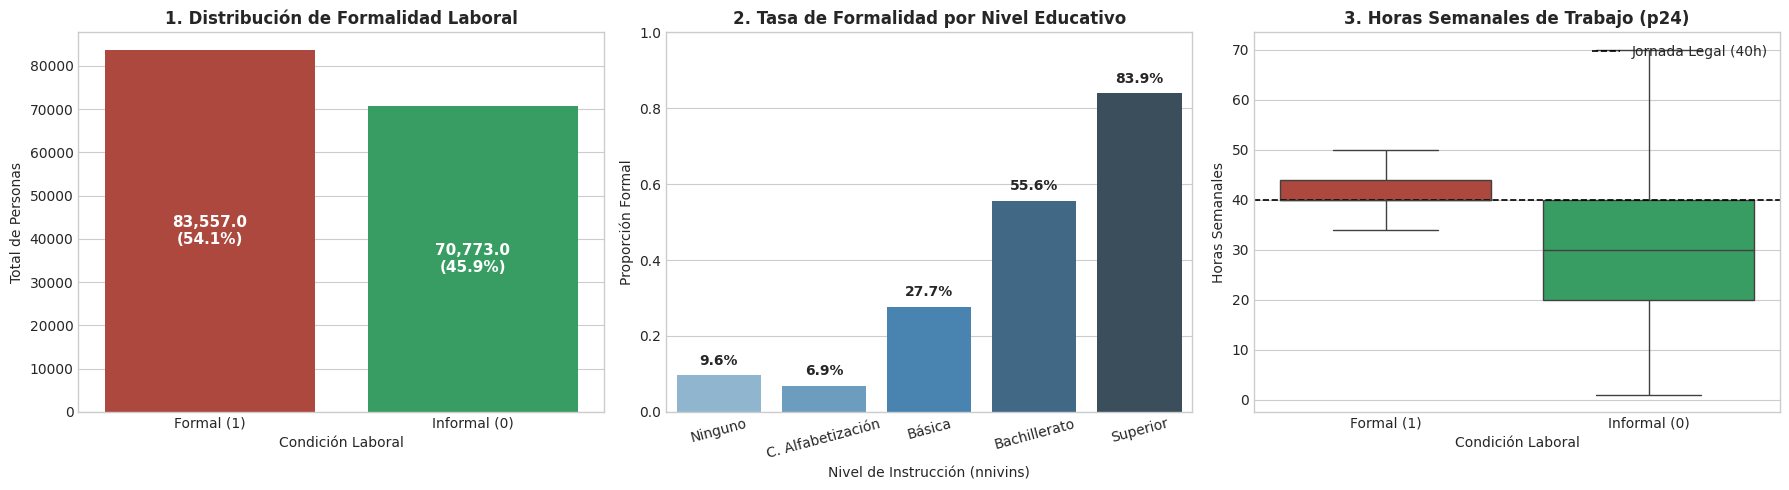

In [ ]:
# ==============================================================================
# FASE 3: ANÁLISIS EXPLORATORIO DE DATOS (EDA) CON ETIQUETAS OFICIALES INEC
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Estilo visual para reportes
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'

# 1. Diccionarios de mapeo según el manual oficial de códigos ENEMDU 2025
mapa_sexo = {1: 'Hombre', 2: 'Mujer'}
mapa_area = {1: 'Urbana', 2: 'Rural'}
mapa_nnivins = {
    1: 'Ninguno',
    2: 'C. Alfabetización',
    3: 'Básica',
    4: 'Bachillerato',
    5: 'Superior'
}
mapa_p47a = {1: '< 100 pers.', 2: '≥ 100 pers.'}

# Creamos una copia local con etiquetas interpretables para visualización
df_plot = df_analisis.copy()
df_plot['sexo_label'] = df_plot['p02'].map(mapa_sexo)
df_plot['area_label'] = df_plot['area'].map(mapa_area)
df_plot['educ_label'] = df_plot['nnivins'].map(mapa_nnivins)
df_plot['tamano_label'] = df_plot['p47a'].map(mapa_p47a)
df_plot['formal_label'] = df_plot['target_formal'].map({0: 'Informal (0)', 1: 'Formal (1)'})

# Tratamiento de horas: excluir código 999 ('No informa') para no distorsionar distribuciones
df_plot_horas = df_plot[df_plot['p24'] < 999].copy()

# ------------------------------------------------------------------------------
# Figura de 3 Paneles Clave para el Informe y Video
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Distribución del Target (Balance de Clases)
sns.countplot(
    data=df_plot,
    x='formal_label',
    palette=['#c0392b', '#27ae60'],
    ax=axes[0]
)
axes[0].set_title('1. Distribución de Formalidad Laboral', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Condición Laboral')
axes[0].set_ylabel('Total de Personas')

total = len(df_plot)
for p in axes[0].patches:
    altura = p.get_height()
    pct = (altura / total) * 100
    axes[0].annotate(f'{altura:,}\n({pct:.1f}%)',
                     (p.get_x() + p.get_width() / 2., altura / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Panel 2: Tasa de Formalidad por Nivel de Instrucción (Eje económico central)
orden_educ = ['Ninguno', 'C. Alfabetización', 'Básica', 'Bachillerato', 'Superior']
tasa_educ = df_plot.groupby('educ_label')['target_formal'].mean().reindex(orden_educ).reset_index()

sns.barplot(
    data=tasa_educ,
    x='educ_label',
    y='target_formal',
    palette='Blues_d',
    ax=axes[1]
)
axes[1].set_title('2. Tasa de Formalidad por Nivel Educativo', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Nivel de Instrucción (nnivins)')
axes[1].set_ylabel('Proporción Formal')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=15)

for p in axes[1].patches:
    valor = p.get_height()
    axes[1].annotate(f'{valor*100:.1f}%',
                     (p.get_x() + p.get_width() / 2., valor + 0.02),
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

# Panel 3: Jornada Semanal Efectiva (Excluyendo código 999)
sns.boxplot(
    data=df_plot_horas,
    x='formal_label',
    y='p24',
    palette=['#c0392b', '#27ae60'],
    ax=axes[2],
    showfliers=False
)
axes[2].set_title('3. Horas Semanales de Trabajo (p24)', fontweight='bold', fontsize=12)
axes[2].set_xlabel('Condición Laboral')
axes[2].set_ylabel('Horas Semanales')
axes[2].axhline(40, color='black', linestyle='--', linewidth=1.2, label='Jornada Legal (40h)')
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

In [ ]:
print(f"Registros con horas = 999 ('No informa'): {(df_analisis['p24'] == 999).sum()}")
print(f"Registros con edad >= 98: {(df_analisis['p03'] >= 98).sum()}")

Registros con horas = 999 ('No informa'): 0
Registros con edad >= 98: 5


In [ ]:
# XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX Cd para volver a conectar la base XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX
# XXXXXXXXXXXXXXXXXXXXX XXXXXXXXXXXXXXXXXXXXXXXXXXX XXXXXXXXXXXXXXXXXXXXXXXXXXX XXXXXXXXXXXXXXXXXXXXX
import sqlite3
import pandas as pd
from google.colab import drive

# 1. Montar Drive para acceder a los archivos
drive.mount('/content/drive')

# 2. Ruta a tu base de datos ya existente
ruta_base_datos = '/content/drive/MyDrive/UIDE/PROYECTO INGRESO/enemdu_2025.db'

# 3. Conectarse y extraer los datos
conexion = sqlite3.connect(ruta_base_datos)
query_extraccion = """
    SELECT
        p02, p03, area, p06, nnivins, p24, p42, p47a, rama1, grupo1, target_formal
    FROM empleo_formalidad;
"""
df_analisis = pd.read_sql_query(query_extraccion, conexion)
conexion.close()

print(f"Base cargada en memoria: {df_analisis.shape[0]:,} filas listas para usar.")

Mounted at /content/drive
Base cargada en memoria: 154,330 filas listas para usar.


In [ ]:
# ==============================================================================
# EXPORTACIÓN DE TABULACIONES DESCRIPTIVAS COMPLETAS A EXCEL (RESPALDO INFORME)
# ==============================================================================
import pandas as pd
import numpy as np

# Ruta donde se guardará el Excel en tu Drive
ruta_excel_salida = '/content/drive/MyDrive/UIDE/PROYECTO INGRESO/Tabulaciones_EDA_ENEMDU_2025.xlsx'

# 1. Etiquetas oficiales según manual del INEC
mapas = {
    'p02': {1: 'Hombre', 2: 'Mujer'},
    'area': {1: 'Urbana', 2: 'Rural'},
    'p06': {
        1: 'Casado(a)', 2: 'Separado(a)', 3: 'Divorciado(a)',
        4: 'Viudo(a)', 5: 'Unión libre', 6: 'Soltero(a)'
    },
    'nnivins': {
        1: 'Ninguno', 2: 'Centro de Alfabetización', 3: 'Educación Básica',
        4: 'Educación Media/Bachillerato', 5: 'Superior'
    },
    'p47a': {1: 'Menos de 100', 2: '100 y más'},
    'p42': {
        1: 'Empleado de gobierno', 2: 'Empleado privado', 3: 'Empleado tercerizado',
        4: 'Jornalero o peón', 5: 'Patrono', 6: 'Cuenta Propia',
        7: 'Trabajador del hogar no remunerado', 8: 'Trabajador no del hogar no remunerado',
        9: 'Ayudante no remunerado de asalariado', 10: 'Empleado(a) Doméstico(a)'
    },
    'grupo1': {
        1: 'Personal direct./admin. pública y empresas',
        2: 'Profesionales científicos e intelectuales',
        3: 'Técnicos y profesionales de nivel medio',
        4: 'Empleados de oficina',
        5: 'Trabajad. de los servicios y comerciantes',
        6: 'Trabajad. calificados agropecuarios y pesqueros',
        7: 'Oficiales operarios y artesanos',
        8: 'Operadores de instalac. máquinas y montad.',
        9: 'Trabajadores no calificados, ocupaciones elementales',
        10: 'Fuerzas Armadas',
        99: 'No especificado'
    },
    'rama1': {
        1: 'A. Agricultura, ganadería, silvicultura y pesca',
        2: 'B. Explotación de minas y canteras',
        3: 'C. Industrias manufactureras',
        4: 'D. Suministros de electricidad, gas',
        5: 'E. Distribución de agua, alcantarillado',
        6: 'F. Construcción',
        7: 'G. Comercio y reparación de vehículos',
        8: 'H. Transporte y almacenamiento',
        9: 'I. Actividades de alojamiento y servicios de comida',
        10: 'J. Información y comunicación',
        11: 'K. Actividades financieras y de seguros',
        12: 'L. Actividades inmobiliarias',
        13: 'M. Actividades profesionales, científicas y técnicas',
        14: 'N. Actividades y servicios administrativos',
        15: 'O. Administración pública, defensa y seg. social',
        16: 'P. Enseñanza',
        17: 'Q. Actividades de atención de la salud humana',
        18: 'R. Artes, entretenimiento y recreación',
        19: 'S. Otras actividades de servicios',
        20: 'T. Hogares privados con servicio doméstico',
        21: 'U. Actividades organizaciones extraterritoriales',
        22: 'No especificado'
    }
}

# DataFrame con etiquetas legibles
df_tab = df_analisis.copy()
df_tab['target_label'] = df_tab['target_formal'].map({0: 'Informal (0)', 1: 'Formal (1)'})
for col, mapping in mapas.items():
    if col in df_tab.columns:
        df_tab[f'{col}_label'] = df_tab[col].map(mapping)

# Función auxiliar para generar tabla cruzada completa (Absolutos, % Fila, % Columna)
def generar_cruce(df, variable_label, nombre_categoria):
    # Frecuencias Absolutas
    ct_abs = pd.crosstab(df[variable_label], df['target_label'], margins=True, margins_name='Total')

    # % en Fila (Tasa de formalidad/informalidad por fila)
    ct_fila = (pd.crosstab(df[variable_label], df['target_label'], normalize='index') * 100).round(2)
    ct_fila.columns = [f'% Fila {c}' for c in ct_fila.columns]

    # % en Columna (Composición de cada sector)
    ct_col = (pd.crosstab(df[variable_label], df['target_label'], normalize='columns') * 100).round(2)
    ct_col.columns = [f'% Col {c}' for c in ct_col.columns]

    # Unir todo en una sola tabla ordenada
    tabla_completa = ct_abs.join(ct_fila).join(ct_col)
    tabla_completa.index.name = nombre_categoria
    return tabla_completa

# 2. Escribir a Excel con pestañas independientes
with pd.ExcelWriter(ruta_excel_salida, engine='openpyxl') as writer:

    # Pestaña 1: Resumen General del Target
    resumen_target = pd.DataFrame({
        'Frecuencia Absoluta': df_tab['target_label'].value_counts(),
        'Porcentaje (%)': (df_tab['target_label'].value_counts(normalize=True) * 100).round(2)
    })
    resumen_target.loc['Total'] = [len(df_tab), 100.0]
    resumen_target.to_excel(writer, sheet_name='00_Target_General')

    # Pestañas de Variables Categóricas
    generar_cruce(df_tab, 'p02_label', 'Sexo (p02)').to_excel(writer, sheet_name='01_Sexo')
    generar_cruce(df_tab, 'area_label', 'Área Geográfica').to_excel(writer, sheet_name='02_Area')
    generar_cruce(df_tab, 'p06_label', 'Estado Civil (p06)').to_excel(writer, sheet_name='03_Estado_Civil')
    generar_cruce(df_tab, 'nnivins_label', 'Nivel Instrucción (nnivins)').to_excel(writer, sheet_name='04_Nivel_Educativo')
    generar_cruce(df_tab, 'p47a_label', 'Tamaño Establecimiento (p47a)').to_excel(writer, sheet_name='05_Tamano_Empresa')
    generar_cruce(df_tab, 'p42_label', 'Categoría Ocupación (p42)').to_excel(writer, sheet_name='06_Cat_Ocupacion')
    generar_cruce(df_tab, 'grupo1_label', 'Grupo Ocupacional (grupo1)').to_excel(writer, sheet_name='07_Grupo_Ocupacional')
    generar_cruce(df_tab, 'rama1_label', 'Rama Actividad (rama1)').to_excel(writer, sheet_name='08_Rama_Actividad')

    # Pestaña 10: Variables Cuantitativas Continuas (Edad y Horas)
    stats_p03 = df_tab.groupby('target_label')['p03'].describe().round(2)
    stats_p03['Variable'] = 'Edad (p03)'

    # Para horas p24 excluimos código 999 si existiera
    df_horas = df_tab[df_tab['p24'] < 999]
    stats_p24 = df_horas.groupby('target_label')['p24'].describe().round(2)
    stats_p24['Variable'] = 'Horas Semanales (p24)'

    tabla_continuas = pd.concat([stats_p03, stats_p24]).reset_index().set_index(['Variable', 'target_label'])
    tabla_continuas.to_excel(writer, sheet_name='09_Variables_Continuas')

print(f"¡Libro Excel de tabulaciones generado exitosamente!\nGuardado en: {ruta_excel_salida}")

¡Libro Excel de tabulaciones generado exitosamente!
Guardado en: /content/drive/MyDrive/UIDE/PROYECTO INGRESO/Tabulaciones_EDA_ENEMDU_2025.xlsx


In [ ]:
# ==============================================================================
# FASE 4 - PASO 1: DIVISIÓN ESTRATIFICADA Y CONSTRUCCIÓN DEL PIPELINE
# ==============================================================================
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Iniciando preparación de datos para Machine Learning...")

# 1. Separar la matriz predictora (X) y el vector objetivo (y)
X = df_analisis.drop(columns=['target_formal'])
y = df_analisis['target_formal']

# 2. Partición 80% Entrenamiento / 20% Prueba con estratificación
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 3. Definir cuáles variables son numéricas y cuáles son categóricas
cols_continuas = ['p03', 'p24']
cols_categoricas = ['p02', 'area', 'p06', 'nnivins', 'p42', 'p47a', 'rama1', 'grupo1']

# 4. Crear el motor de transformación (Pipeline)
preprocesador = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), cols_continuas),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cols_categoricas)
    ]
)

# 5. Entrenar el transformador SOLO con los datos de entrenamiento para evitar Fuga de Datos
X_train_transformado = preprocesador.fit_transform(X_train)
X_test_transformado = preprocesador.transform(X_test)

print("\n--- Validación de Partición y Preprocesamiento ---")
print(f"Total observaciones de Entrenamiento (80%): {X_train_transformado.shape[0]:,} filas")
print(f"Total observaciones de Prueba (20%):        {X_test_transformado.shape[0]:,} filas")
print(f"Número de características finales tras aplicar One-Hot Encoding: {X_train_transformado.shape[1]} columnas")

Iniciando preparación de datos para Machine Learning...

--- Validación de Partición y Preprocesamiento ---
Total observaciones de Entrenamiento (80%): 123,464 filas
Total observaciones de Prueba (20%):        30,866 filas
Número de características finales tras aplicar One-Hot Encoding: 51 columnas


In [ ]:
# ==============================================================================
# FASE 4 - PASO 3: ENTRENAMIENTO DE LOS MODELOS DE MACHINE LEARNING
# ==============================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import time

print("Iniciando el entrenamiento de los algoritmos. Esto tomará un par de minutos...\n")

# 1. Instanciar los modelos con semillas fijas para reproducibilidad
modelo_logistico = LogisticRegression(max_iter=1000, random_state=42)
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
modelo_gb = GradientBoostingClassifier(n_estimators=100, random_state=42)

# 2. Entrenar Regresión Logística
start_time = time.time()
print("Entrenando Regresión Logística...")
modelo_logistico.fit(X_train_transformado, y_train)
print(f"✓ Regresión Logística lista ({time.time() - start_time:.2f} segundos)")

# 3. Entrenar Random Forest
start_time = time.time()
print("Entrenando Random Forest (Bosque Aleatorio)...")
modelo_rf.fit(X_train_transformado, y_train)
print(f"✓ Random Forest listo ({time.time() - start_time:.2f} segundos)")

# 4. Entrenar Gradient Boosting
start_time = time.time()
print("Entrenando Gradient Boosting...")
modelo_gb.fit(X_train_transformado, y_train)
print(f"✓ Gradient Boosting listo ({time.time() - start_time:.2f} segundos)")

print("\n¡Los tres modelos han sido entrenados exitosamente!")

Iniciando el entrenamiento de los algoritmos. Esto tomará un par de minutos...

Entrenando Regresión Logística...
✓ Regresión Logística lista (3.84 segundos)
Entrenando Random Forest (Bosque Aleatorio)...
✓ Random Forest listo (16.93 segundos)
Entrenando Gradient Boosting...
✓ Gradient Boosting listo (30.98 segundos)

¡Los tres modelos han sido entrenados exitosamente!


Evaluando los modelos con el 20% de datos de prueba (30,866 registros)...



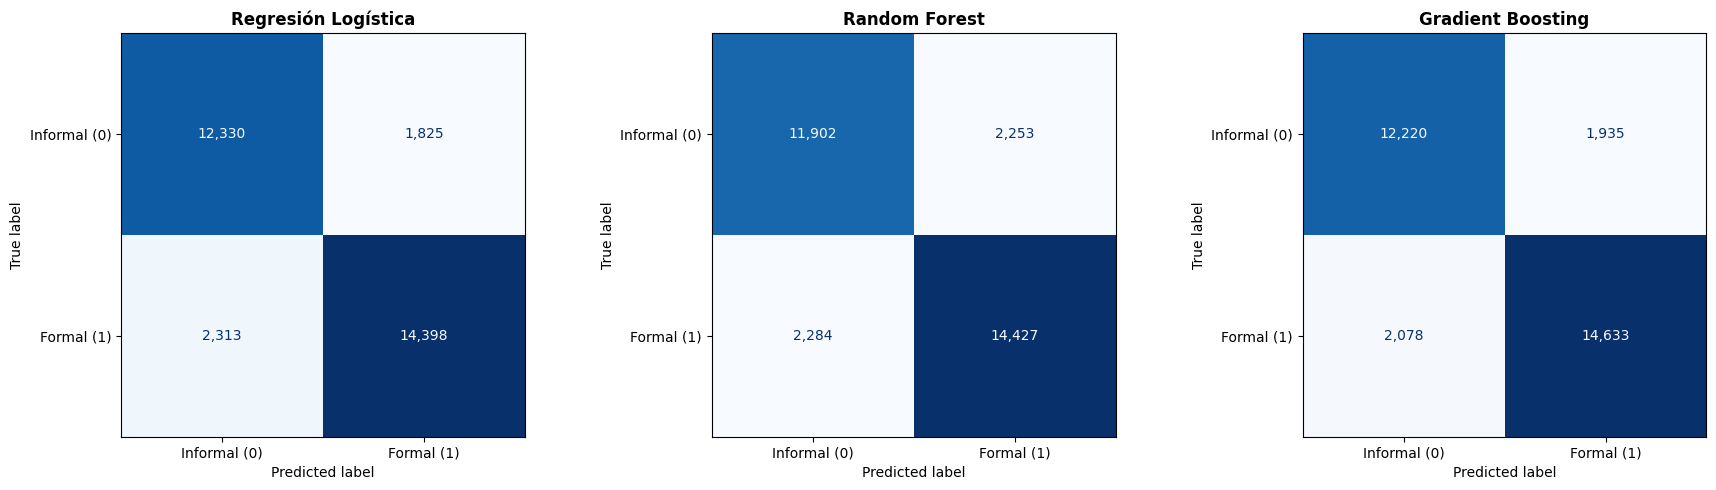


--- COMPARATIVA DE RENDIMIENTO (MÉTRICAS CLAVE) ---


,Exactitud,Precisión,Sensibilidad (Recall),F1-Score,ROC-AUC
Modelo,,,,,
Regresión Logística,0.8659,0.8875,0.8616,0.8744,0.9417
Random Forest,0.8530,0.8649,0.8633,0.8641,0.9303
Gradient Boosting,0.8700,0.8832,0.8757,0.8794,0.9450


In [ ]:
# ==============================================================================
# FASE 4 - PASO 4: EVALUACIÓN DE DESEMPEÑO Y MATRICES DE CONFUSIÓN
# ==============================================================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

print("Evaluando los modelos con el 20% de datos de prueba (30,866 registros)...\n")

# 1. Diccionario con los modelos entrenados
modelos = {
    'Regresión Logística': modelo_logistico,
    'Random Forest': modelo_rf,
    'Gradient Boosting': modelo_gb
}

resultados = []
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 2. Bucle de evaluación para cada modelo
for idx, (nombre, modelo) in enumerate(modelos.items()):
    # Generar predicciones de clase y probabilidades
    y_pred = modelo.predict(X_test_transformado)
    y_prob = modelo.predict_proba(X_test_transformado)[:, 1]

    # Calcular métricas de evaluación
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_prob)

    resultados.append({
        'Modelo': nombre,
        'Exactitud': acc,
        'Precisión': prec,
        'Sensibilidad (Recall)': rec,
        'F1-Score': f1,
        'ROC-AUC': roc
    })

    # Generar gráfico de la Matriz de Confusión
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Informal (0)', 'Formal (1)'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False, values_format=',d')

    axes[idx].set_title(f'{nombre}', fontweight='bold')
    axes[idx].grid(False)

plt.tight_layout()
plt.show()

# 3. Mostrar tabla consolidada de métricas
df_resultados = pd.DataFrame(resultados).set_index('Modelo')
print("\n--- COMPARATIVA DE RENDIMIENTO (MÉTRICAS CLAVE) ---")
display(df_resultados.round(4))

Extrayendo la importancia de las variables del Gradient Boosting...

--- TOP 15 VARIABLES MÁS DETERMINANTES ---


,Variable_Transformada,Impacto (%)
0,p42_2.0,32.06
1,p47a_2.0,23.37
2,p24,12.64
3,nnivins_5.0,7.82
4,grupo1_9.0,3.34
5,p42_6.0,3.02
6,grupo1_6.0,2.69
7,p42_4.0,2.31
8,grupo1_5.0,2.05
9,area_2,1.89


/tmp/ipykernel_1592/1329731761.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


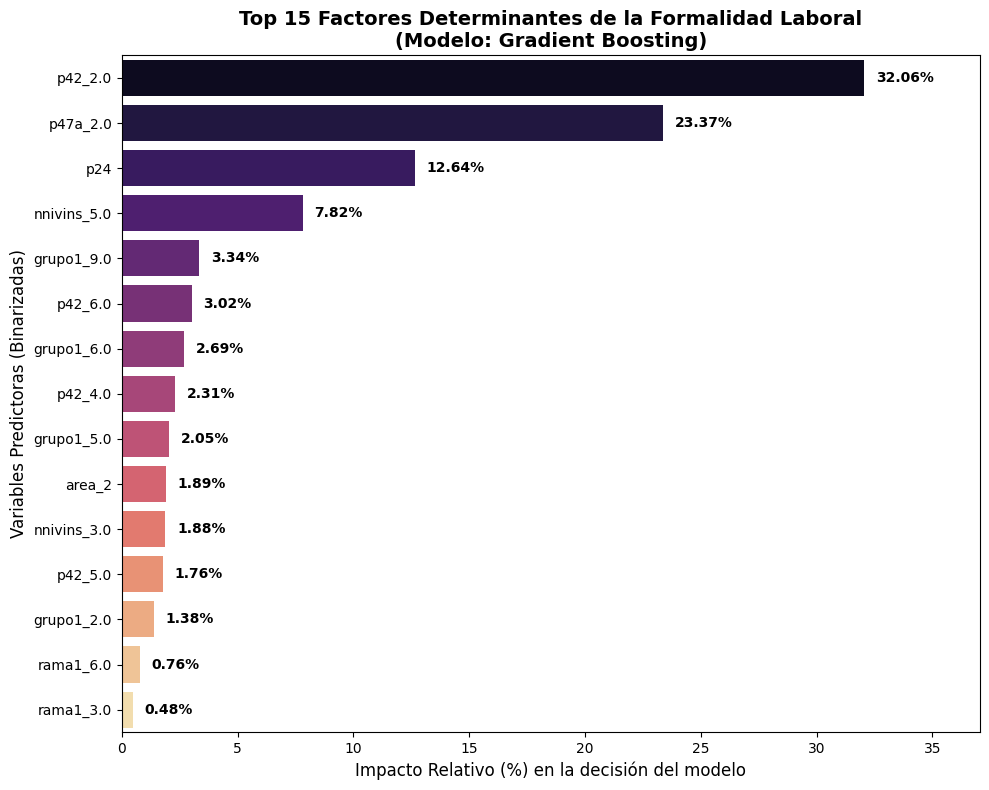

In [ ]:
# ==============================================================================
# FASE 4 - PASO 5: IMPORTANCIA DE LAS VARIABLES (FEATURE IMPORTANCE)
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Extrayendo la importancia de las variables del Gradient Boosting...\n")

# 1. Extraer los nombres de las 51 columnas generadas por el preprocesador
nombres_transformados = preprocesador.get_feature_names_out()

# Limpiar los prefijos 'num__' y 'cat__' que añade Scikit-Learn automáticamente
nombres_limpios = [nombre.replace('num__', '').replace('cat__', '') for nombre in nombres_transformados]

# 2. Extraer los pesos de importancia del mejor modelo (Gradient Boosting)
importancias = modelo_gb.feature_importances_

# 3. Crear un DataFrame para organizar y ordenar los datos
df_importancias = pd.DataFrame({
    'Variable_Transformada': nombres_limpios,
    'Importancia_Relativa': importancias
})

# Ordenar de mayor a menor importancia
df_importancias = df_importancias.sort_values(by='Importancia_Relativa', ascending=False).reset_index(drop=True)

# Crear una columna de porcentaje para facilitar la lectura
df_importancias['Impacto (%)'] = (df_importancias['Importancia_Relativa'] * 100).round(2)

# 4. Mostrar las 15 variables de mayor impacto en formato tabla
print("--- TOP 15 VARIABLES MÁS DETERMINANTES ---")
display(df_importancias[['Variable_Transformada', 'Impacto (%)']].head(15))

# 5. Generar un gráfico de barras horizontal para el Informe/Video
plt.figure(figsize=(10, 8))
sns.barplot(
    data=df_importancias.head(15),
    x='Impacto (%)',
    y='Variable_Transformada',
    palette='magma'
)

plt.title('Top 15 Factores Determinantes de la Formalidad Laboral\n(Modelo: Gradient Boosting)', fontweight='bold', fontsize=14)
plt.xlabel('Impacto Relativo (%) en la decisión del modelo', fontsize=12)
plt.ylabel('Variables Predictoras (Binarizadas)', fontsize=12)

# Añadir las etiquetas de datos en las barras
for index, value in enumerate(df_importancias['Impacto (%)'].head(15)):
    plt.text(value + 0.5, index, f'{value}%', va='center', fontweight='bold', color='black')

plt.xlim(0, df_importancias['Impacto (%)'].max() + 5)
plt.tight_layout()
plt.show()